# Assignment 05: Machine Learning for Genomic Data
**Aim:** Classify genomic samples (cancer sub-types / normal tissue) from gene-expression features using **Random Forest** and **SVM**, evaluate the models, and interpret important genes.

**Dataset:** Real microarray gene-expression data from Kaggle - **CuMiDa (Curated Microarray Database)**, e.g. *Leukemia gene expression (GSE9476)* or *Brain cancer gene expression (GSE50161)* - tumour sub-types and normal tissue.

**Workflow:** Load data -> Preprocess -> Train/test split -> Train models -> Evaluate -> Compare -> Feature importance

## 1. Import libraries

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

np.random.seed(42)

## 2. Load genomic data (Kaggle dataset)
**Before running:** download the dataset from Kaggle (see the steps given with this notebook), extract it, and set `DATA_PATH` below to the CSV file on your computer.

File layout (CuMiDa): each **row = one sample**, columns = `samples` (sample ID), `type` (class label, e.g. leukemia sub-type names / *normal*), then thousands of **gene/probe expression columns**.

In [4]:
# ====== CHANGE ONLY THESE LINES ======
DATA_PATH = r"Leukemia_GSE9476.csv"   # <- path of your downloaded CSV
LABEL_COL = "type"        # column holding the class label (CuMiDa uses 'type')
ID_COLS   = ["samples"]   # non-feature columns to drop (sample IDs)
# =====================================

data = pd.read_csv(DATA_PATH)
print("Raw shape:", data.shape)
data.iloc[:5, :6]

Raw shape: (64, 22285)


,samples,type,1007_s_at,1053_at,117_at,121_at
0,1,Bone_Marrow_CD34,7.745245,7.811210,6.477916,8.841506
1,12,Bone_Marrow_CD34,8.087252,7.240673,8.584648,8.983571
2,13,Bone_Marrow_CD34,7.792056,7.549368,11.053504,8.909703
3,14,Bone_Marrow_CD34,7.767265,7.094460,11.816433,8.994654
4,15,Bone_Marrow_CD34,8.010117,7.405281,6.656049,9.050682


## 3. Explore and preprocess
Steps: separate features and label, drop ID column, keep numeric gene columns only, check missing values, and encode the text labels (each class gets a number).

In [5]:
# Separate label and features
y_text = data[LABEL_COL].astype(str)
X = data.drop(columns=[LABEL_COL] + [c for c in ID_COLS if c in data.columns])

# Keep only numeric gene columns
X = X.select_dtypes(include=[np.number])

print("Samples x Genes:", X.shape)
print("Missing values:", int(X.isna().sum().sum()))
print("Class counts:\n", y_text.value_counts())

# Fill any missing value with the gene's median (usually none in CuMiDa)
if X.isna().sum().sum() > 0:
    X = X.fillna(X.median())

# Encode text labels -> numbers
le = LabelEncoder()
y = pd.Series(le.fit_transform(y_text), index=X.index, name="label")
class_names = list(le.classes_)
print("Label encoding:", dict(zip(class_names, range(len(class_names)))))

# Binary problem -> 'binary' metrics, multi-class -> 'weighted' metrics
AVG = "binary" if len(class_names) == 2 else "weighted"

# For binary data make the DISEASE class the positive class (so Precision/Recall refer to disease)
healthy_words = ("normal", "control", "healthy", "non")
POS = 1
for i, n in enumerate(class_names):
    if not any(w in n.lower() for w in healthy_words):
        POS = i
print("Positive (disease) class:", class_names[POS] if AVG == "binary" else "n/a (multi-class)")
KW = {"pos_label": POS} if AVG == "binary" else {}

Samples x Genes: (64, 22283)
Missing values: 0
Class counts:
 type
AML                 26
Bone_Marrow         10
PB                  10
PBSC_CD34           10
Bone_Marrow_CD34     8
Name: count, dtype: int64
Label encoding: {'AML': 0, 'Bone_Marrow': 1, 'Bone_Marrow_CD34': 2, 'PB': 3, 'PBSC_CD34': 4}
Positive (disease) class: n/a (multi-class)


Split into **80% training / 20% testing** (stratified keeps class ratio equal).
Features are **scaled** (needed for SVM) inside a pipeline so the test data never leaks into training.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (51, 22283)  Test: (13, 22283)


## 4. Train models

In [7]:
rf  = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
svm = make_pipeline(StandardScaler(), SVC(kernel="linear", random_state=42))

rf.fit(X_train, y_train)
svm.fit(X_train, y_train)
print("Training complete")

Training complete


## 5. Evaluate models
Metrics: **Accuracy**, **Precision**, **Recall**, **F1-score**, plus 5-fold cross-validation accuracy.

In [8]:
models = {"Random Forest": rf, "SVM": svm}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []

for name, model in models.items():
    pred = model.predict(X_test)
    rows.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, average=AVG, zero_division=0, **KW),
        "Recall":    recall_score(y_test, pred, average=AVG, zero_division=0, **KW),
        "F1-score":  f1_score(y_test, pred, average=AVG, zero_division=0, **KW),
        "CV Accuracy (5-fold)": cross_val_score(model, X, y, cv=cv).mean(),
    })

results = pd.DataFrame(rows).set_index("Model").round(3)
results

,Accuracy,Precision,Recall,F1-score,CV Accuracy (5-fold)
Model,,,,,
Random Forest,0.923,0.936,0.923,0.914,0.985
SVM,1.000,1.000,1.000,1.000,0.985


In [9]:
for name, model in models.items():
    print("=====", name, "=====")
    print(classification_report(y_test, model.predict(X_test), target_names=class_names, zero_division=0))

===== Random Forest =====
                  precision    recall  f1-score   support

             AML       0.83      1.00      0.91         5
     Bone_Marrow       1.00      1.00      1.00         2
Bone_Marrow_CD34       1.00      0.50      0.67         2
              PB       1.00      1.00      1.00         2
       PBSC_CD34       1.00      1.00      1.00         2

        accuracy                           0.92        13
       macro avg       0.97      0.90      0.92        13
    weighted avg       0.94      0.92      0.91        13

===== SVM =====
                  precision    recall  f1-score   support

             AML       1.00      1.00      1.00         5
     Bone_Marrow       1.00      1.00      1.00         2
Bone_Marrow_CD34       1.00      1.00      1.00         2
              PB       1.00      1.00      1.00         2
       PBSC_CD34       1.00      1.00      1.00         2

        accuracy                           1.00        13
       macro avg       1.

### Confusion matrices

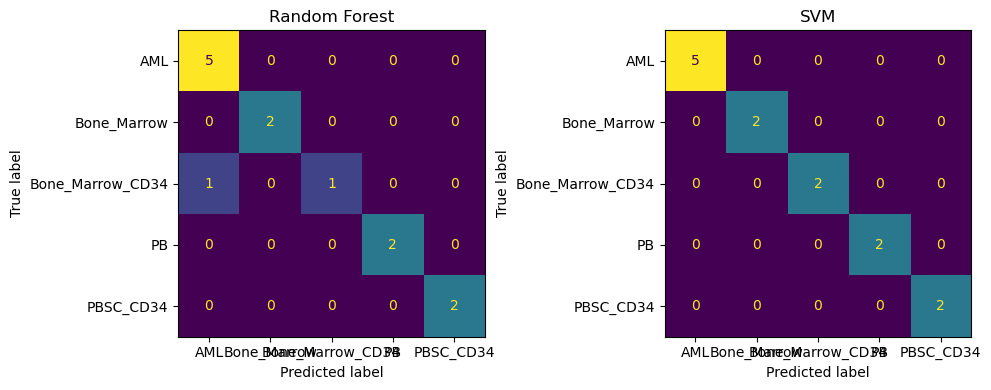

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

## 6. Model comparison

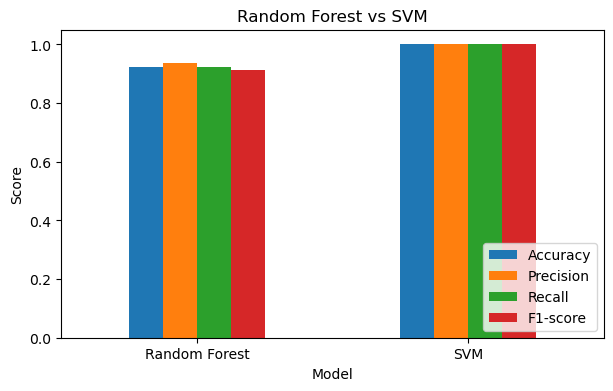

Best model (by F1-score): SVM


In [11]:
results[["Accuracy", "Precision", "Recall", "F1-score"]].plot(kind="bar", figsize=(7, 4), ylim=(0, 1.05))
plt.title("Random Forest vs SVM"); plt.ylabel("Score"); plt.xticks(rotation=0)
plt.legend(loc="lower right"); plt.show()

best = results["F1-score"].idxmax()
print("Best model (by F1-score):", best)

## 7. Feature importance (which genes matter?)
Random Forest gives an importance score for every gene. Genes with high scores are candidate **biomarkers**.
(In CuMiDa the column names are Affymetrix **probe IDs**, e.g. `1007_s_at`; look them up on GEO / NCBI / GeneCards to get the gene symbol.)

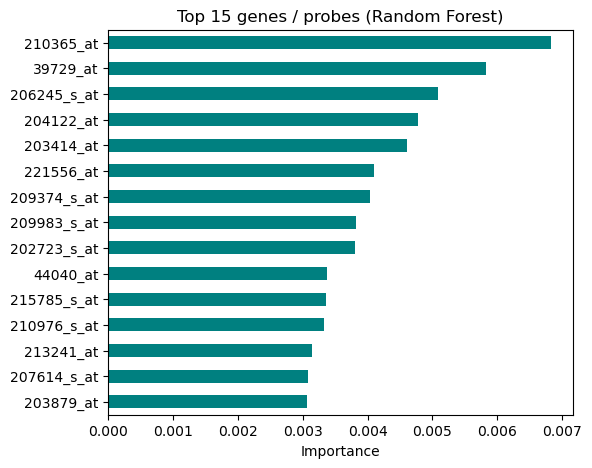

210365_at      0.006830
39729_at       0.005820
206245_s_at    0.005092
204122_at      0.004782
203414_at      0.004603
221556_at      0.004095
209374_s_at    0.004041
209983_s_at    0.003820
202723_s_at    0.003803
44040_at       0.003367
dtype: float64

In [12]:
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
top = importance.head(15)

top[::-1].plot(kind="barh", figsize=(6, 5), color="teal")
plt.xlabel("Importance"); plt.title("Top 15 genes / probes (Random Forest)")
plt.show()

top.head(10)

## 8. Conclusion
- Write which model gave the higher Accuracy / F1-score on the real dataset.
- Mention the top genes found by Random Forest and that they are candidate biomarkers for the studied disease.
- Note: gene expression data has **many more features (genes) than samples**, so cross-validation is used to confirm the results are not due to a lucky split.